# Лабораторная работа №3. Оптимизация гиперпараметров

**Цель:** научиться честно подбирать гиперпараметры модели с помощью кросс-валидации, сравнить Grid Search и Random Search и понять, как гиперпараметры влияют на качество.

**Задача и данные** - из лабораторной №2: по данным пассажира Титаника предсказать, выжил он (`Survived` = 1) или нет (0). Датасет [Titanic Dataset](https://www.kaggle.com/datasets/yasserh/titanic-dataset), 891 пассажир. Метрика та же - F1 для класса "выжил".

**Модель - Gradient Boosting.** Почему именно она:
- в лабораторной №2 её параметры были заданы заранее, без подбора, и по CV бустинг был слабее леса (F1 0.744 против 0.760) - есть что улучшать;
- у неё три понятных и действительно важных гиперпараметра: число деревьев, шаг обучения и глубина дерева. Число деревьев и шаг связаны между собой, поэтому их нужно подбирать вместе - как раз задача для перебора;
- у бустинга хорошо видны и недообучение, и переобучение, а их нужно найти по ТЗ. Случайный лес почти не переобучается, поэтому для этой работы он менее показателен.

Модель выбрана по её свойствам и результатам CV из лабораторной №2, а не по результатам на test.

**Baseline этой работы** - бустинг с параметрами из лабораторной №2.

**План:** 1) настройки; 2) данные и разбиение (как в лабораторной №2); 3) кросс-валидация; 4) baseline; 5) гиперпараметры; 6) Grid Search; 7) Random Search; 8) влияние гиперпараметров; 9) анализ устойчивости; 10) финальная модель и test; 11) сохранение модели; 12) итоги.

## 1. Настройки

In [1]:
# Установка библиотек - нужна один раз, если их ещё нет (раскомментировать и выполнить):
# %pip install numpy pandas matplotlib seaborn joblib scipy "scikit-learn>=1.4"

In [2]:
import io
import time
import urllib.request
import zipfile
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from scipy.stats import loguniform, randint
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, make_scorer, precision_score, recall_score
from sklearn.model_selection import (
    GridSearchCV,
    ParameterGrid,
    RandomizedSearchCV,
    StratifiedKFold,
    cross_val_score,
    cross_validate,
    train_test_split,
    validation_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

# параметры эксперимента
RANDOM_STATE = 42    # одно зерно для разбиения, фолдов CV, модели и случайного поиска
TEST_SIZE = 0.2      # доля тестовой выборки, как в лабораторной №2
N_FOLDS = 5          # число фолдов кросс-валидации на train (почему 5 - раздел 3)
N_JOBS = -1          # считать на всех ядрах процессора: быстрее, на результат не влияет
TARGET = "Survived"

DATA_DIR = Path("data")
DATA_PATH = DATA_DIR / "Titanic-Dataset.csv"
MODEL_PATH = Path("model.joblib")
KAGGLE_URL = "https://www.kaggle.com/api/v1/datasets/download/yasserh/titanic-dataset"

sns.set_theme()  # стандартное оформление графиков seaborn
pd.set_option("display.precision", 4)

- `RANDOM_STATE = 42` везде - при каждом запуске получаются одни и те же разбиения, модели и результаты поиска. Меняться может только время выполнения: оно зависит от компьютера.
- `TEST_SIZE` и `RANDOM_STATE` такие же, как в лабораторной №2, поэтому train и test - те же самые пассажиры.

## 2. Данные и разбиение (как в лабораторной №2)
Подготовка данных та же, что в лабораторной №2: те же признаки, то же разбиение, та же предобработка. Подробный анализ данных и объяснение каждого решения - в лабораторной №2 (разделы 2-6), здесь только код.

### 2.1. Загрузка

In [3]:
def load_titanic() -> pd.DataFrame:
    # Читает Titanic-Dataset.csv из data/; если файла нет - скачивает архив с Kaggle
    if not DATA_PATH.exists():
        print(f"{DATA_PATH} не найден - скачиваем архив с Kaggle")
        DATA_DIR.mkdir(parents=True, exist_ok=True)
        with urllib.request.urlopen(KAGGLE_URL, timeout=60) as response:
            archive = zipfile.ZipFile(io.BytesIO(response.read()))
        DATA_PATH.write_bytes(archive.read(DATA_PATH.name))  # в архиве один файл Titanic-Dataset.csv
    return pd.read_csv(DATA_PATH)


df = load_titanic()
assert df.shape == (891, 12), "ожидается 891 пассажир и 12 столбцов, как на Kaggle"
print(f"{df.shape[0]} строк, {df.shape[1]} столбцов")
print(f"Выжили: {df[TARGET].sum()} из {len(df)} ({df[TARGET].mean():.1%})")

891 строк, 12 столбцов
Выжили: 342 из 891 (38.4%)


### 2.2. Признаки
9 признаков, как в лабораторной №2:
- 7 исходных: `Pclass`, `Sex`, `Age`, `SibSp`, `Parch`, `Fare`, `Embarked`;
- `Title` - обращение из имени (Mr, Mrs, Miss, Master, остальные - Rare);
- `FamilySize = SibSp + Parch + 1`.

Не используем `PassengerId`, `Name`, `Ticket` (идентификаторы) и `Cabin` (77% пропусков).

In [4]:
TITLE_SYNONYMS = {"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"}
COMMON_TITLES = ["Mr", "Mrs", "Miss", "Master"]  # остальные обращения -> "Rare"
FEATURES = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked", "Title", "FamilySize"]


def make_features(data: pd.DataFrame) -> pd.DataFrame:
    # Из таблицы в формате Kaggle делает 9 признаков модели.
    # Каждая строка обрабатывается отдельно, статистики по данным не считаются,
    # пропуски не заполняются (это сделает Pipeline).
    out = data[["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]].copy()
    title = data["Name"].str.extract(r",\s*([^.]+)\.", expand=False).replace(TITLE_SYNONYMS)
    out["Title"] = title.where(title.isin(COMMON_TITLES), "Rare")
    out["FamilySize"] = data["SibSp"] + data["Parch"] + 1
    return out[FEATURES]


X = make_features(df)
y = df[TARGET]
assert TARGET not in X.columns  # целевая переменная не попала в признаки
X.head()

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Title,FamilySize
0,3,male,22.0,1,0,7.2500,S,Mr,2
1,1,female,38.0,1,0,71.2833,C,Mrs,2
2,3,female,26.0,0,0,7.9250,S,Miss,1
3,1,female,35.0,1,0,53.1000,S,Mrs,2
4,3,male,35.0,0,0,8.0500,S,Mr,1


### 2.3. Разбиение на train и test
80/20 со стратификацией по `Survived` и `random_state=42` - те же параметры, что в лабораторной №2. Строки до разбиения не удаляем и не переставляем, поэтому получаются те же 712 пассажиров в train и 179 в test.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,  # доля выживших в train и test одинаковая
)
split_table = pd.DataFrame({
    "пассажиров": [len(y_train), len(y_test)],
    "погибших (0)": [(y_train == 0).sum(), (y_test == 0).sum()],
    "выживших (1)": [y_train.sum(), y_test.sum()],
    "доля выживших, %": [y_train.mean() * 100, y_test.mean() * 100],
}, index=["train", "test"])
display(split_table.round(2))

assert X_train.index.intersection(X_test.index).empty  # ни один пассажир не попал в обе части
assert (y_test == 0).sum() == 110 and y_test.sum() == 69  # то же, что в лабораторной №2

,пассажиров,погибших (0),выживших (1),"доля выживших, %"
train,712,439,273,38.34
test,179,110,69,38.55


**Вывод:**
- Train - 712 пассажиров, test - 179 (110 погибших и 69 выживших), как в лабораторной №2. Значит, результаты двух работ можно сравнивать напрямую.
- **Test дальше не используется до раздела 10.** Всё, что касается гиперпараметров, решаем только по кросс-валидации на train.

### 2.4. Предобработка
Пропуски заполняем и категории кодируем внутри `Pipeline`, поэтому медиана и список категорий каждый раз считаются только по той части данных, на которой модель учится. Масштабирование бустингу не нужно: деревья задают вопросы вида "Fare > 50?", и ответ не зависит от масштаба.

In [6]:
NUM_COLS = ["Age", "SibSp", "Parch", "Fare", "FamilySize"]
CAT_COLS = ["Pclass", "Sex", "Embarked", "Title"]


def make_preprocessor():
    # Заполнение пропусков и one-hot кодирование (как в лабораторной №2, без масштабирования)
    num = Pipeline([("impute", SimpleImputer(strategy="median"))])
    cat = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    return ColumnTransformer([("num", num, NUM_COLS), ("cat", cat, CAT_COLS)], verbose_feature_names_out=False)


def make_gb(**params):
    # Pipeline "предобработка + бустинг"; params - гиперпараметры бустинга, остальные - по умолчанию
    return Pipeline([
        ("prep", make_preprocessor()),
        ("model", GradientBoostingClassifier(random_state=RANDOM_STATE, **params)),
    ])


prep_demo = make_preprocessor().fit(X_train)  # только для проверки размерности, обучается на train
print(f"Признаков до предобработки: {X_train.shape[1]}, после: {len(prep_demo.get_feature_names_out())}")

Признаков до предобработки: 9, после: 18


После one-hot получается 18 столбцов: 5 числовых и 13 столбцов 0/1 (3 класса, 2 пола, 3 порта, 5 обращений) - как в лабораторной №2. Функция `make_gb` собирает Pipeline с бустингом - она понадобится во всех разделах.

## 3. Кросс-валидация

### 3.1. Вопросы из ТЗ
**Зачем нужна кросс-валидация.** Чтобы сравнивать варианты модели на данных, которых модель не видела при обучении, не трогая test. Train делится на 5 частей (фолдов): модель 5 раз учится на 4 частях и проверяется на оставшейся. Каждый пассажир train ровно один раз попадает в проверочную часть. В итоге получаем 5 оценок: их среднее - качество модели, а разброс показывает, насколько этой оценке можно верить.

**Почему одного разбиения train/test недостаточно для подбора параметров.**
- Оценка на одной небольшой выборке очень шумная. В test 179 пассажиров, из них 69 выживших. Один угаданный или пропущенный пассажир меняет F1 примерно на 0.01, а разные наборы гиперпараметров обычно отличаются на 0.01-0.02. Кто победит на одном разбиении - во многом дело случая.
- Одно разбиение даёт одно число без разброса, и непонятно, настоящая разница между вариантами или случайная. Кросс-валидация даёт 5 оценок и их разброс.

**Что будет, если многократно выбирать гиперпараметры по результату на test.**
- Мы выберем вариант, которому повезло именно на этих 179 пассажирах. Результат на test станет завышенным, а на новых данных качество окажется ниже.
- Чем больше вариантов сравниваем по test, тем сильнее завышение: среди сотни вариантов почти наверняка найдётся случайно удачный.
- По сути test превратится в часть обучения, и честной оценки модели не останется. По ТЗ это критическая ошибка, поэтому в этой работе test используется один раз - в разделе 10.

### 3.2. Сколько фолдов
- В train 712 пассажиров. При **5 фолдах** модель учится на 570 (80% train) и проверяется на 142, из них около 55 выживших.
- При 3 фолдах модель учится только на 2/3 train - качество будет занижено сильнее, и для оценки разброса всего 3 числа.
- При 10 фолдах в проверочной части 71 пассажир (около 27 выживших): одна ошибка меняет F1 фолда на 0.02-0.03, оценки по фолдам очень шумные. И считать в 2 раза дольше, а при переборе обучаются сотни моделей.
- 5 фолдов - компромисс между этими крайностями. К тому же это те же 5 фолдов, что в лабораторной №2: baseline можно сравнить с ней напрямую.

In [7]:
# одни и те же 5 фолдов во всей работе: random_state фиксирован, поэтому разбиение одинаковое при каждом вызове
cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)

# F1 для класса 1; zero_division=0 - если модель ни разу не сказала "выжил", F1 считаем нулём, без предупреждений
F1 = make_scorer(f1_score, zero_division=0)

fold_rows = {}
for i, (train_idx, val_idx) in enumerate(cv.split(X_train, y_train), start=1):
    fold_rows[f"фолд {i}"] = {
        "учится на": len(train_idx),
        "проверяется на": len(val_idx),
        "выживших в проверочной части": y_train.iloc[val_idx].sum(),
        "доля выживших, %": y_train.iloc[val_idx].mean() * 100,
    }
pd.DataFrame(fold_rows).T.round(1)

,учится на,проверяется на,выживших в проверочной части,"доля выживших, %"
фолд 1,569.0,143.0,55.0,38.5
фолд 2,569.0,143.0,55.0,38.5
фолд 3,570.0,142.0,55.0,38.7
фолд 4,570.0,142.0,54.0,38.0
фолд 5,570.0,142.0,54.0,38.0


**Вывод:**
- В каждом фолде модель учится на 569-570 пассажирах и проверяется на 142-143, в проверочной части 54-55 выживших.
- Доля выживших во всех фолдах одинаковая (около 38%) - это делает `StratifiedKFold`. Поэтому фолды сравнимы между собой.
- Этот объект `cv` используется во всех разделах: baseline, Grid Search и Random Search проверяются на одних и тех же фолдах, и сравнение между ними честное.

## 4. Baseline: бустинг с параметрами из лабораторной №2
Как работает бустинг: деревья строятся по очереди, каждое новое неглубокое дерево исправляет ошибки всех предыдущих. Вклад каждого дерева умножается на шаг обучения `learning_rate`. Ответ модели - сумма вкладов всех деревьев, переведённая в вероятность выжить.

Параметры baseline - те же, что в лабораторной №2 (там они взяты из лабораторной №1, без подбора):

| Параметр | Значение |
|---|---|
| `n_estimators` (число деревьев) | 200 |
| `learning_rate` (шаг) | 0.05 |
| `max_depth` (глубина дерева) | 3 |
| остальные | по умолчанию scikit-learn |

In [8]:
BASELINE_PARAMS = {"n_estimators": 200, "learning_rate": 0.05, "max_depth": 3}
baseline = make_gb(**BASELINE_PARAMS)

start = time.perf_counter()
# на одном ядре (без n_jobs) - чтобы увидеть, сколько стоит одна кросс-валидация
baseline_cv = cross_validate(baseline, X_train, y_train, cv=cv, scoring=F1, return_train_score=True)
baseline_time = time.perf_counter() - start

baseline_folds = pd.DataFrame({
    "train F1": baseline_cv["train_score"],
    "CV F1": baseline_cv["test_score"],
}, index=[f"фолд {i + 1}" for i in range(N_FOLDS)])
display(baseline_folds.T.round(4))

print(f"CV F1 = {baseline_cv['test_score'].mean():.4f} (std {baseline_cv['test_score'].std():.4f}), "
      f"от {baseline_cv['test_score'].min():.4f} до {baseline_cv['test_score'].max():.4f}")
print(f"train F1 = {baseline_cv['train_score'].mean():.4f}")
print(f"Время одной кросс-валидации (5 обучений на одном ядре): {baseline_time:.2f} с")

,фолд 1,фолд 2,фолд 3,фолд 4,фолд 5
train F1,0.9031,0.8947,0.8814,0.8910,0.8910
CV F1,0.7963,0.7170,0.7475,0.6923,0.7677


CV F1 = 0.7441 (std 0.0366), от 0.6923 до 0.7963
train F1 = 0.8922
Время одной кросс-валидации (5 обучений на одном ядре): 1.97 с


**Вывод:**
- CV F1 baseline - 0.744, как в лабораторной №2: те же данные, те же фолды, те же параметры. Это точка отсчёта: подбор гиперпараметров должен её превзойти.
- От фолда к фолду F1 меняется от 0.69 до 0.80 (std 0.037). Значит, разница между вариантами меньше 0.03-0.04 может оказаться случайной - это важно помнить при сравнении.
- На train F1 0.892 - заметно выше, чем на CV. Модель частично запоминает обучающих пассажиров, то есть уже немного переобучена. Проверим, исправит ли это подбор.
- Одна кросс-валидация на одном ядре занимает 1-2 секунды (точное время зависит от компьютера). Перебор из сотни комбинаций - это несколько минут на одном ядре и меньше минуты на всех ядрах. Такой бюджет приемлемый.

## 5. Гиперпараметры
Гиперпараметры - это настройки модели, которые задаются до обучения, а не выучиваются из данных. Берём три, от которых у бустинга больше всего зависит сложность модели. Остальные (`subsample`, `min_samples_leaf` и др.) оставляем по умолчанию: ТЗ просит не раздувать пространство поиска.

| Гиперпараметр | Смысл | Диапазон | Как может повлиять |
|---|---|---|---|
| `n_estimators` | сколько деревьев строит бустинг, то есть сколько раз модель исправляет свои ошибки | 50-800 | мало деревьев - модель не успевает выучить закономерности (недообучение); слишком много - начинает подгоняться под отдельных пассажиров (переобучение) |
| `learning_rate` | шаг: с каким весом каждое новое дерево добавляется к ответу | 0.01-0.3 | маленький шаг - модель учится медленно и аккуратно, нужно много деревьев; большой шаг - учится быстро, но легче переобучается |
| `max_depth` | глубина каждого дерева: сколько вопросов подряд оно задаёт, то есть сколько признаков учитывает одновременно | 1-6 | глубина 1 - каждое дерево смотрит на один признак, взаимодействий нет; глубина 5-6 - дерево может описать узкую группу из нескольких пассажиров и запомнить её |

Почему такие диапазоны:
- `n_estimators` и `learning_rate` работают в паре: примерно важно их произведение - насколько далеко в сумме модель уходит от начального ответа. У baseline это 200 x 0.05 = 10. В сетке оно меняется от 50 x 0.01 = 0.5 (модель почти ничего не выучит) до 800 x 0.3 = 240 (модель точно переобучится). Значит, в диапазон попадают обе крайности.
- `learning_rate` берём по логарифмической шкале (0.01, 0.03, 0.1, 0.3): важно, во сколько раз меняется шаг, а не на сколько. Переход от 0.01 к 0.03 так же заметен, как от 0.1 к 0.3.
- `max_depth` до 6: у бустинга обычно мелкие деревья, глубже 6 на 570 пассажирах деревья уже запоминают единичные случаи.

## 6. Grid Search
Grid Search (полный перебор) проверяет **все** комбинации значений из заранее заданной сетки. Каждая комбинация оценивается кросс-валидацией на тех же 5 фолдах, что и baseline, и побеждает комбинация с лучшим средним CV F1.

### 6.1. Пространство поиска

In [9]:
# "model__" - гиперпараметр шага "model" внутри Pipeline (то есть самого бустинга)
PARAM_GRID = {
    "model__n_estimators": [50, 100, 200, 400, 800],
    "model__learning_rate": [0.01, 0.03, 0.1, 0.3],
    "model__max_depth": [1, 2, 3, 4, 6],
}
n_grid = len(ParameterGrid(PARAM_GRID))
print(f"Комбинаций: {n_grid} (5 x 4 x 5), обучений модели: {n_grid} x {N_FOLDS} фолдов = {n_grid * N_FOLDS}")

Комбинаций: 100 (5 x 4 x 5), обучений модели: 100 x 5 фолдов = 500


### 6.2. Поиск

In [10]:
grid_search = GridSearchCV(
    make_gb(),               # бустинг без заданных параметров - их подставит поиск
    PARAM_GRID,
    scoring=F1,
    cv=cv,                   # те же 5 фолдов, что у baseline
    return_train_score=True, # F1 на обучающих фолдах - понадобится в разделе 8
    n_jobs=N_JOBS,
)  # refit=True (по умолчанию): после поиска лучшая комбинация обучается на всём train

start = time.perf_counter()
grid_search.fit(X_train, y_train)
grid_time = time.perf_counter() - start


def search_table(search):
    # Результаты поиска: по строке на комбинацию, отсортированы по CV F1
    res = pd.DataFrame(search.cv_results_)
    table = pd.DataFrame({
        "n_estimators": res["param_model__n_estimators"].astype(int),
        "learning_rate": res["param_model__learning_rate"].astype(float),
        "max_depth": res["param_model__max_depth"].astype(int),
        "train F1": res["mean_train_score"],
        "CV F1": res["mean_test_score"],
        "CV F1 std": res["std_test_score"],
    })
    return table.sort_values("CV F1", ascending=False)


def total_fit_time(search):
    # суммарное время всех обучений и проверок (как если бы считали на одном ядре)
    res = search.cv_results_
    return (res["mean_fit_time"] + res["mean_score_time"]).sum() * N_FOLDS


grid_table = search_table(grid_search)
baseline_f1 = baseline_cv["test_score"].mean()
grid_best = grid_table.iloc[0]

print("Лучшие гиперпараметры:", {k.replace("model__", ""): v for k, v in grid_search.best_params_.items()})
print(f"CV F1 лучшей комбинации: {grid_search.best_score_:.4f} (std {grid_best['CV F1 std']:.4f}), "
      f"baseline: {baseline_f1:.4f}, разница: {grid_search.best_score_ - baseline_f1:+.4f}")
print(f"Время поиска: {grid_time:.1f} с на всех ядрах, суммарно {total_fit_time(grid_search):.0f} с на одном ядре")
print(f"Комбинаций лучше baseline: {(grid_table['CV F1'] > baseline_f1).sum()} из {n_grid}")
print(f"Комбинаций, уступающих лучшей меньше чем на 0.01: {(grid_table['CV F1'] > grid_search.best_score_ - 0.01).sum()}")

grid_table.head(10).round(4)

Лучшие гиперпараметры: {'learning_rate': 0.3, 'max_depth': 1, 'n_estimators': 100}
CV F1 лучшей комбинации: 0.7713 (std 0.0354), baseline: 0.7441, разница: +0.0272
Время поиска: 43.7 с на всех ядрах, суммарно 428 с на одном ядре
Комбинаций лучше baseline: 66 из 100
Комбинаций, уступающих лучшей меньше чем на 0.01: 16


,n_estimators,learning_rate,max_depth,train F1,CV F1,CV F1 std
76,100,0.30,1,0.7843,0.7713,0.0354
66,100,0.10,4,0.9281,0.7681,0.0113
42,200,0.03,4,0.8992,0.7681,0.0207
18,400,0.01,4,0.8828,0.7676,0.0356
19,800,0.01,4,0.9135,0.7673,0.0268
65,50,0.10,4,0.8966,0.7668,0.0362
79,800,0.30,1,0.8428,0.7666,0.0286
43,400,0.03,4,0.9376,0.7658,0.0195
67,200,0.10,4,0.9665,0.7648,0.0215
41,100,0.03,4,0.8666,0.7644,0.0345


**Вывод:**
- Лучшая комбинация: **100 деревьев, шаг 0.3, глубина 1**. CV F1 0.771 против 0.744 у baseline (+0.027). Проверено 100 комбинаций (500 обучений), поиск занял меньше минуты на всех ядрах.
- Прирост меньше разброса между фолдами (std около 0.035 у обеих моделей), поэтому уверенно сказать, что подобранная модель лучше, пока нельзя. Проверим по отдельным фолдам в разделе 9.
- Победитель - простая модель: деревья глубины 1, каждое смотрит на один признак. На train F1 0.784, почти как на CV, то есть переобучения нет. У baseline на train 0.892.
- Второе место (100 деревьев, шаг 0.1, глубина 4) по CV почти такое же (0.768), но устроено иначе: глубокие деревья и 0.928 на train. Разница в 0.003 - случайность, победитель выбран просто по большему среднему.

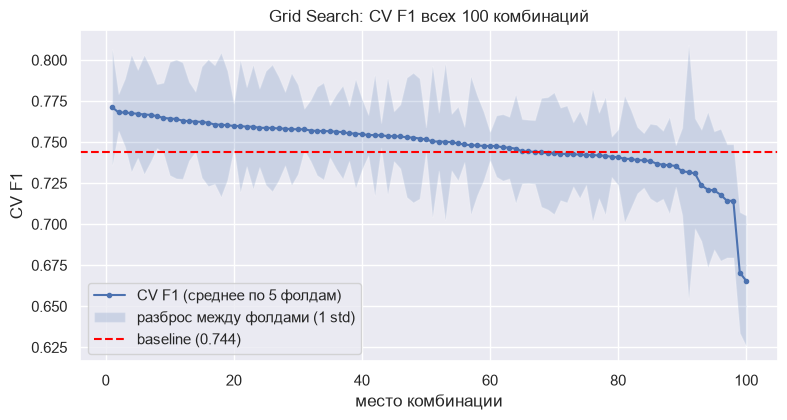

In [11]:
# все 100 комбинаций по убыванию CV F1: насколько лучшая выделяется среди остальных
ranks = np.arange(1, n_grid + 1)
plt.figure(figsize=(9, 4.3))
plt.plot(ranks, grid_table["CV F1"], marker=".", label="CV F1 (среднее по 5 фолдам)")
plt.fill_between(ranks, grid_table["CV F1"] - grid_table["CV F1 std"], grid_table["CV F1"] + grid_table["CV F1 std"],
                 alpha=0.2, label="разброс между фолдами (1 std)")
plt.axhline(baseline_f1, color="red", linestyle="--", label=f"baseline ({baseline_f1:.3f})")
plt.xlabel("место комбинации")
plt.ylabel("CV F1")
plt.title("Grid Search: CV F1 всех 100 комбинаций")
plt.legend()
plt.show()

**Вывод:**
- 66 комбинаций из 100 лучше baseline, 16 уступают лучшей меньше чем на 0.01. Кривая почти плоская, и полоса разброса у каждой комбинации шире, чем разница между соседними.
- Значит, какая именно комбинация окажется первой, во многом случайно: на других фолдах первой могла бы стать другая из верхней части.
- Резко хуже только последние комбинации (ниже 0.72): это мало деревьев с маленьким шагом, модель просто не успевает обучиться. Подробнее - в разделе 8.

## 7. Random Search
Random Search (случайный поиск) не перебирает всё, а берёт заданное число случайных комбинаций. Значения выбираются не из короткого списка, а из распределений на тех же интервалах, что у сетки.

### 7.1. Пространство поиска и бюджет
- `n_estimators` - любое целое от 50 до 800;
- `learning_rate` - от 0.01 до 0.3, равномерно по логарифмической шкале: значения от 0.01 до 0.03 выпадают так же часто, как от 0.1 до 0.3 (как в сетке);
- `max_depth` - целое от 1 до 6 (сюда попадает и глубина 5, которой нет в сетке).

Бюджет тот же, что у Grid Search: 100 комбинаций, каждая проверяется на тех же 5 фолдах, то есть 500 обучений.

In [12]:
PARAM_DISTRIBUTIONS = {
    "model__n_estimators": randint(50, 801),        # целое от 50 до 800 (правая граница не включается)
    "model__learning_rate": loguniform(0.01, 0.3),  # от 0.01 до 0.3, равномерно по логарифмической шкале
    "model__max_depth": randint(1, 7),              # целое от 1 до 6
}
N_ITER = n_grid  # тот же бюджет, что у Grid Search

random_search = RandomizedSearchCV(
    make_gb(),
    PARAM_DISTRIBUTIONS,
    n_iter=N_ITER,
    scoring=F1,
    cv=cv,                      # те же 5 фолдов
    return_train_score=True,
    n_jobs=N_JOBS,
    random_state=RANDOM_STATE,  # те же случайные комбинации при каждом запуске
)

start = time.perf_counter()
random_search.fit(X_train, y_train)
random_time = time.perf_counter() - start

random_table = search_table(random_search)
random_best = random_table.iloc[0]

print("Лучшие гиперпараметры:", {"n_estimators": int(random_best["n_estimators"]),
                                  "learning_rate": round(float(random_best["learning_rate"]), 4),
                                  "max_depth": int(random_best["max_depth"])})
print(f"CV F1 лучшей комбинации: {random_search.best_score_:.4f} (std {random_best['CV F1 std']:.4f}), "
      f"Grid Search: {grid_search.best_score_:.4f}, baseline: {baseline_f1:.4f}")
print(f"Время поиска: {random_time:.1f} с на всех ядрах, суммарно {total_fit_time(random_search):.0f} с на одном ядре")
print(f"Комбинаций лучше baseline: {(random_table['CV F1'] > baseline_f1).sum()} из {N_ITER}")

random_table.head(10).round(4)

Лучшие гиперпараметры: {'n_estimators': 180, 'learning_rate': 0.2834, 'max_depth': 1}
CV F1 лучшей комбинации: 0.7706 (std 0.0270), Grid Search: 0.7713, baseline: 0.7441
Время поиска: 57.8 с на всех ядрах, суммарно 657 с на одном ядре
Комбинаций лучше baseline: 78 из 100


,n_estimators,learning_rate,max_depth,train F1,CV F1,CV F1 std
12,180,0.2834,1,0.7976,0.7706,0.0270
6,326,0.0206,4,0.9066,0.7701,0.0326
28,542,0.0260,4,0.9454,0.7692,0.0045
53,522,0.0301,4,0.9525,0.7690,0.0133
5,463,0.0121,4,0.8977,0.7689,0.0219
1,70,0.1206,5,0.9564,0.7670,0.0307
95,519,0.0285,4,0.9497,0.7669,0.0189
84,282,0.2013,1,0.7997,0.7668,0.0307
56,308,0.1616,1,0.7946,0.7668,0.0316
78,522,0.0996,1,0.7940,0.7668,0.0316


**Вывод:**
- Лучшая комбинация: **180 деревьев, шаг 0.283, глубина 1**. Почти то же, что у Grid Search (100 деревьев, шаг 0.3, глубина 1). CV F1 0.7706 против 0.7713 - разница 0.001, по сравнению с разбросом между фолдами это ничто.
- Два поиска независимо пришли в одну и ту же область: деревья глубины 1 с большим шагом. Значит, победитель Grid Search - не случайная точка сетки.
- В верхней части таблицы снова есть и второй тип моделей: глубина 4, маленький шаг, много деревьев (CV F1 около 0.769). Одна из них (542 дерева, шаг 0.026) очень стабильна: std всего 0.0045.

### 7.2. Сравнение с Grid Search

In [13]:
def search_summary(search, table, wall_time):
    # Главные характеристики поиска для сравнения
    return {
        "комбинаций": len(table),
        "лучший CV F1": search.best_score_,
        "std лучшей": table.iloc[0]["CV F1 std"],
        "время, с (все ядра)": wall_time,
        "время, с (сумма на одном ядре)": total_fit_time(search),
        "среднее число деревьев": table["n_estimators"].mean(),
        "разных n_estimators": table["n_estimators"].nunique(),
        "разных learning_rate": table["learning_rate"].nunique(),
        "разных max_depth": table["max_depth"].nunique(),
    }


search_compare = pd.DataFrame({
    "Grid Search": search_summary(grid_search, grid_table, grid_time),
    "Random Search": search_summary(random_search, random_table, random_time),
}).T
search_compare.round(4)

,комбинаций,лучший CV F1,std лучшей,"время, с (все ядра)","время, с (сумма на одном ядре)",среднее число деревьев,разных n_estimators,разных learning_rate,разных max_depth
Grid Search,100.0,0.7713,0.0354,43.6713,428.3287,310.00,5.0,4.0,5.0
Random Search,100.0,0.7706,0.0270,57.7957,657.1935,447.13,94.0,100.0,6.0


**Вывод:**
- **Качество** одинаковое: 0.771 у обоих поисков.
- **Комбинаций** тоже одинаково (100), но Random Search проверил 94 разных значения числа деревьев и 100 разных шагов, а Grid Search - только 5 и 4. Пространство случайный поиск просмотрел гораздо подробнее.
- **По времени** Random Search в 1.3-1.5 раза дольше (точные секунды немного меняются от запуска к запуску). Дело не в методе, а в числе деревьев: в среднем у него 447 деревьев на комбинацию, у сетки - 310 (в сетке значения 50, 100, 200, 400, 800, а здесь любое от 50 до 800 с равной вероятностью). Бустинг учится тем дольше, чем больше деревьев. То есть одинаковое число комбинаций ещё не означает одинаковое время.

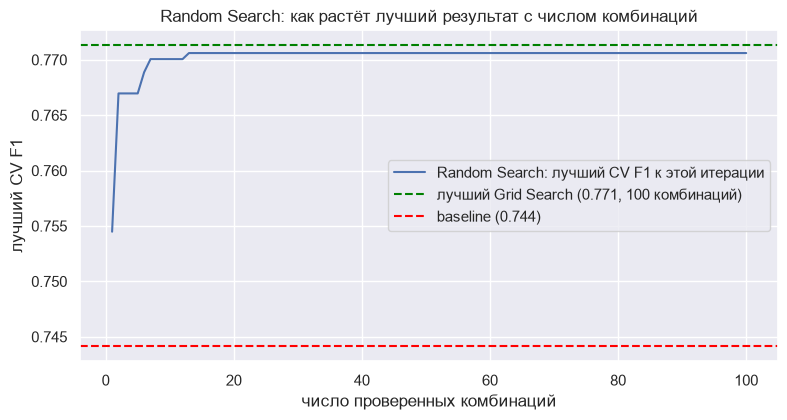

Комбинаций Random Search, уступающих лучшему Grid меньше 0.01: 22 из 100 (22%)
В этом запуске первая такая комбинация найдена на итерации 2
Вероятность найти хотя бы одну такую за 5 итераций: 71%
Вероятность найти хотя бы одну такую за 10 итераций: 92%
Вероятность найти хотя бы одну такую за 20 итераций: 99%


In [14]:
# лучший CV F1, найденный к каждой итерации случайного поиска (комбинации в том порядке, в котором их выбрал поиск)
best_so_far = np.maximum.accumulate(random_search.cv_results_["mean_test_score"])
iterations = np.arange(1, N_ITER + 1)

plt.figure(figsize=(9, 4.3))
plt.plot(iterations, best_so_far, label="Random Search: лучший CV F1 к этой итерации")
plt.axhline(grid_search.best_score_, color="green", linestyle="--",
            label=f"лучший Grid Search ({grid_search.best_score_:.3f}, 100 комбинаций)")
plt.axhline(baseline_f1, color="red", linestyle="--", label=f"baseline ({baseline_f1:.3f})")
plt.xlabel("число проверенных комбинаций")
plt.ylabel("лучший CV F1")
plt.title("Random Search: как растёт лучший результат с числом комбинаций")
plt.legend()
plt.show()

# насколько легко случайно попасть в "хорошую" область: доля комбинаций, уступающих лучшему Grid меньше 0.01
near = random_table["CV F1"] >= grid_search.best_score_ - 0.01
share = near.mean()
first = iterations[best_so_far >= grid_search.best_score_ - 0.01][0]
print(f"Комбинаций Random Search, уступающих лучшему Grid меньше 0.01: {near.sum()} из {N_ITER} ({share:.0%})")
print(f"В этом запуске первая такая комбинация найдена на итерации {first}")
for k in [5, 10, 20]:
    # каждая итерация - независимая попытка, поэтому шанс ни разу не попасть равен (1 - share) в степени k
    print(f"Вероятность найти хотя бы одну такую за {k} итераций: {1 - (1 - share) ** k:.0%}")

**Вывод:**
- Комбинацию, уступающую лучшей из Grid Search меньше чем на 0.01, случайный поиск нашёл уже на 2-й итерации, а свой лучший результат - на 13-й. Следующие 87 итераций ничего не улучшили.
- Это не просто везение: таких "хороших" комбинаций 22%. Поэтому за 10 случайных итераций хотя бы одна из них находится с вероятностью 92%, за 20 - 99%.
- На этой задаче хватило бы 10-20 итераций случайного поиска вместо 100 комбинаций сетки, то есть в 5-10 раз меньше вычислений.

### 7.3. Когда случайный поиск лучше полного перебора
- **Параметров много.** Сетка растёт как произведение: 3 параметра по 5 значений - 125 комбинаций, 6 параметров - уже 15 625. У случайного поиска число комбинаций задаётся напрямую (`n_iter`) и от числа параметров не зависит.
- **Важны не все параметры.** Если от какого-то параметра качество почти не зависит, сетка тратит большую часть бюджета на перебор его значений, а важный параметр проверяет всего в 4-5 точках. В случайном поиске каждая итерация - новое значение каждого параметра (у нас 100 разных шагов против 4).
- **Параметры непрерывные** (шаг, сила регуляризации). Заранее неизвестно, какие точки ставить в сетку, а случайный поиск пробует любые значения из интервала.
- **Бюджет ограничен.** Случайный поиск можно остановить в любой момент: даже 10 итераций уже покрывают всё пространство. А сетка перебирает комбинации по порядку: остановленная после первой четверти, она проверила бы только шаг 0.01.
- **Grid Search лучше**, когда параметров 1-2 и значений немного: тогда полный перебор недорогой и проверяет каждую точку. Так мы выбирали глубину дерева в лабораторной №2.

## 8. Влияние гиперпараметров
Меняем один-два гиперпараметра и смотрим на F1 на train и на CV:
- **недообучение** - низкое качество и на train, и на CV: модель слишком простая и не выучила даже обучающие данные;
- **разумная сложность** - CV F1 близок к максимуму, а разрыв между train и CV небольшой;
- **переобучение** - train F1 продолжает расти, а CV F1 падает или стоит на месте: модель запоминает обучающих пассажиров, а не общие закономерности.

Всё считается по CV на train, test не используется.

### 8.1. Число деревьев при разных шагах
Для каждого фолда обучаем одну модель из 1000 деревьев. Метод `staged_predict` выдаёт её прогнозы после 1, 2, ..., 1000 деревьев, поэтому видно качество при любом числе деревьев, а обучать 1000 моделей не нужно. Глубина 3, как у baseline.

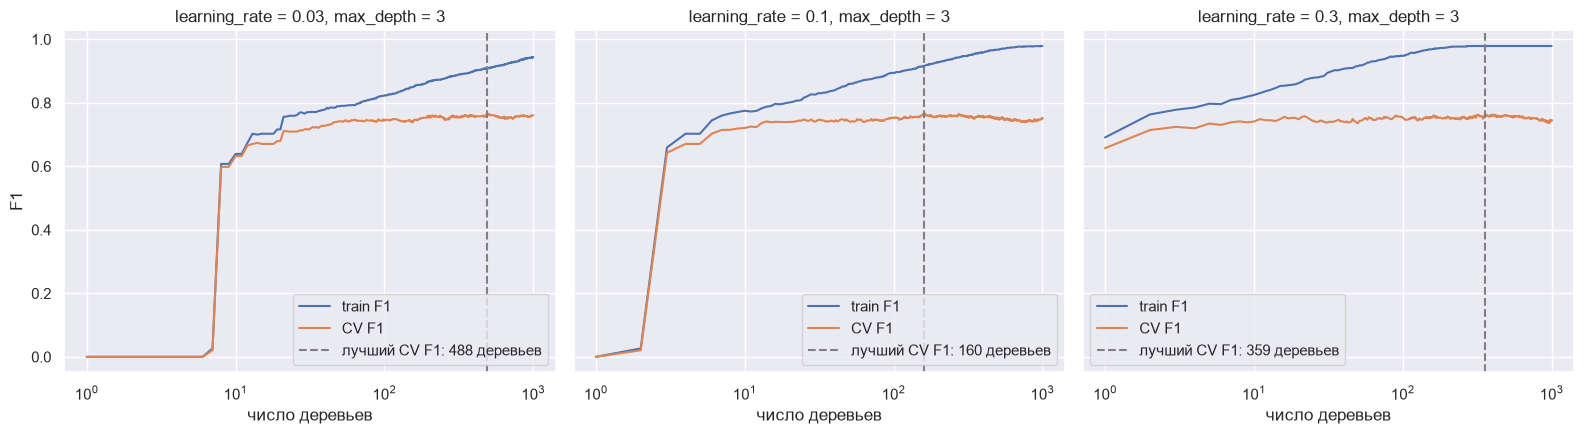

,деревьев до CV F1 > 0.70,лучшее число деревьев,лучший CV F1,train F1 там же,CV F1 при 1000,train F1 при 1000
learning_rate = 0.03,21.0,488.0,0.7665,0.9076,0.7603,0.9441
learning_rate = 0.1,6.0,160.0,0.7664,0.9159,0.7505,0.9788
learning_rate = 0.3,2.0,359.0,0.7638,0.9789,0.7451,0.9788


In [15]:
N_MAX = 1000                 # максимальное число деревьев на кривой
STAGED_RATES = [0.03, 0.1, 0.3]


def staged_f1(n_max, **params):
    # Средний F1 на train и на CV после каждого дерева (от 1 до n_max)
    train_f1, cv_f1 = np.zeros(n_max), np.zeros(n_max)
    for train_idx, val_idx in cv.split(X_train, y_train):
        X_tr, y_tr = X_train.iloc[train_idx], y_train.iloc[train_idx]
        X_val, y_val = X_train.iloc[val_idx], y_train.iloc[val_idx]
        pipe = make_gb(n_estimators=n_max, **params).fit(X_tr, y_tr)  # предобработка тоже учится только на X_tr
        prep, gb = pipe.named_steps["prep"], pipe.named_steps["model"]
        train_f1 += [f1_score(y_tr, pred, zero_division=0) for pred in gb.staged_predict(prep.transform(X_tr))]
        cv_f1 += [f1_score(y_val, pred, zero_division=0) for pred in gb.staged_predict(prep.transform(X_val))]
    return train_f1 / N_FOLDS, cv_f1 / N_FOLDS


staged = {lr: staged_f1(N_MAX, learning_rate=lr, max_depth=3) for lr in STAGED_RATES}
n_trees = np.arange(1, N_MAX + 1)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, (lr, (train_f1, cv_f1)) in zip(axes, staged.items()):
    ax.plot(n_trees, train_f1, label="train F1")
    ax.plot(n_trees, cv_f1, label="CV F1")
    ax.axvline(n_trees[cv_f1.argmax()], color="gray", linestyle="--", label=f"лучший CV F1: {cv_f1.argmax() + 1} деревьев")
    ax.set_xscale("log")  # логарифмическая шкала: видно и первые деревья, и сотни деревьев
    ax.set_title(f"learning_rate = {lr}, max_depth = 3")
    ax.set_xlabel("число деревьев")
    ax.legend()
axes[0].set_ylabel("F1")
plt.tight_layout()
plt.show()

staged_rows = {}
for lr, (train_f1, cv_f1) in staged.items():
    staged_rows[f"learning_rate = {lr}"] = {
        "деревьев до CV F1 > 0.70": n_trees[cv_f1 > 0.70][0],
        "лучшее число деревьев": cv_f1.argmax() + 1,
        "лучший CV F1": cv_f1.max(),
        "train F1 там же": train_f1[cv_f1.argmax()],
        "CV F1 при 1000": cv_f1[-1],
        "train F1 при 1000": train_f1[-1],
    }
pd.DataFrame(staged_rows).T.round(4)

**Вывод:**
- **Недообучение - первые деревья.** Бустинг начинает с одинакового ответа для всех - доли выживших (38%). Это меньше 0.5, поэтому сначала модель всем говорит "погиб", и F1 = 0 и на train, и на CV. При шаге 0.03 CV F1 выше 0.70 появляется только к 21-му дереву, при шаге 0.3 - уже ко 2-му.
- **Разумная сложность - широкое плато:** CV F1 0.75-0.77 примерно от 50 до 500 деревьев. Лучшие значения при трёх шагах почти одинаковые (0.766, 0.766, 0.764) - при подходящем числе деревьев любой из этих шагов даёт то же качество.
- **Переобучение - правая часть:** train F1 растёт до 0.979, а CV F1 понемногу падает (при шаге 0.3 - с 0.764 до 0.745 к 1000 деревьям). Выше 0.979 train F1 не поднимается: у части пассажиров одинаковые признаки и разный исход (лабораторная №2, раздел 2.4).
- **Чем больше шаг, тем быстрее модель проходит все стадии:** при шаге 0.03 к 1000 деревьям train F1 ещё 0.944, а при 0.1 и 0.3 модель уже давно на потолке и только запоминает train.

### 8.2. Глубина дерева
Остальные параметры - как у лучшей модели Grid Search (100 деревьев, шаг 0.3). `validation_curve` - это та же кросс-валидация на тех же фолдах, только для одного параметра.

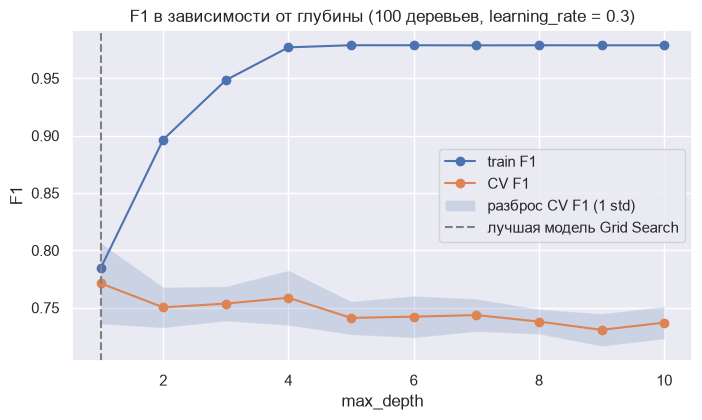

max_depth,1,2,3,4,5,6,7,8,9,10
train F1,0.7843,0.8966,0.9483,0.9770,0.9788,0.9788,0.9787,0.9788,0.9787,0.9787
CV F1,0.7713,0.7503,0.7536,0.7587,0.7411,0.7422,0.7436,0.7379,0.7307,0.7370
CV F1 std,0.0354,0.0178,0.0152,0.0240,0.0146,0.0183,0.0144,0.0109,0.0143,0.0142


In [16]:
GRID_BEST = {name.replace("model__", ""): value for name, value in grid_search.best_params_.items()}


def param_curve(name, values):
    # F1 на train и на CV при разных значениях одного гиперпараметра, остальные - как у лучшей модели Grid Search
    fixed = {k: v for k, v in GRID_BEST.items() if k != name}
    train_scores, cv_scores = validation_curve(
        make_gb(**fixed), X_train, y_train,
        param_name=f"model__{name}", param_range=values,
        cv=cv, scoring=F1, n_jobs=N_JOBS,
    )
    return pd.DataFrame({
        "train F1": train_scores.mean(axis=1),
        "CV F1": cv_scores.mean(axis=1),
        "CV F1 std": cv_scores.std(axis=1),
    }, index=pd.Index(values, name=name))


def plot_curve(table, title, logx=False):
    # train F1, CV F1 и разброс CV F1 между фолдами; вертикальная линия - значение у лучшей модели Grid Search
    x = table.index.to_numpy()
    plt.figure(figsize=(8, 4.3))
    plt.plot(x, table["train F1"], marker="o", label="train F1")
    plt.plot(x, table["CV F1"], marker="o", label="CV F1")
    plt.fill_between(x, table["CV F1"] - table["CV F1 std"], table["CV F1"] + table["CV F1 std"],
                     alpha=0.2, label="разброс CV F1 (1 std)")
    plt.axvline(GRID_BEST[table.index.name], color="gray", linestyle="--", label="лучшая модель Grid Search")
    if logx:
        plt.xscale("log")
    plt.xlabel(table.index.name)
    plt.ylabel("F1")
    plt.title(title)
    plt.legend()
    plt.show()


depth_curve = param_curve("max_depth", list(range(1, 11)))
plot_curve(depth_curve, "F1 в зависимости от глубины (100 деревьев, learning_rate = 0.3)")
depth_curve.round(4).T

**Вывод:**
- **Переобучение начинается сразу после глубины 1:** train F1 растёт с 0.784 до 0.977 уже при глубине 4, а CV F1 падает с 0.771 до 0.75-0.76. С глубины 5 train на потолке, а CV - 0.73-0.74: глубокие деревья с большим шагом быстро запоминают обучающих пассажиров. Разрыв train - CV - 0.013 при глубине 1 и 0.24 при глубине 10.
- **Области недообучения у глубины нет:** лучший результат уже у деревьев глубины 1. Каждое такое дерево задаёт один вопрос по одному признаку, а главные закономерности в данных как раз такие: пол или обращение, класс, цена билета. 100 простых деревьев складывают их вместе.
- Где начинается переобучение, зависит от шага: при шаге 0.01-0.1 хорошо работает и глубина 4 (раздел 6), а при шаге 0.3 она уже слишком большая.

### 8.3. Шаг обучения
Остальные параметры - как у лучшей модели Grid Search (100 деревьев, глубина 1). Берём и значения за пределами сетки (0.001, 0.003 и 1.0), чтобы увидеть крайности.

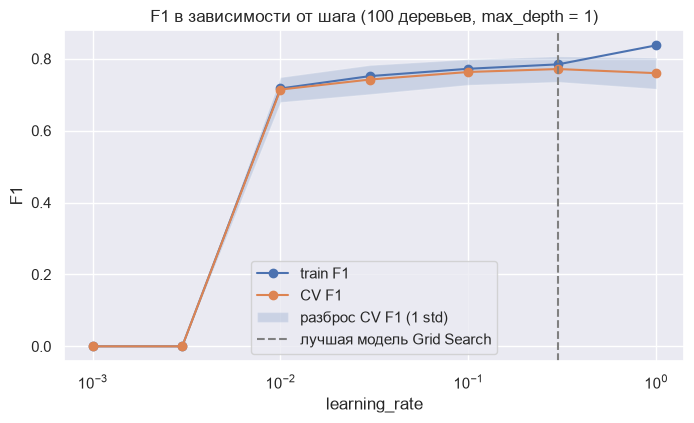

learning_rate,0.001,0.003,0.010,0.030,0.100,0.300,1.000
train F1,0.0,0.0,0.7172,0.7517,0.7720,0.7843,0.8372
CV F1,0.0,0.0,0.7143,0.7422,0.7631,0.7713,0.7598
CV F1 std,0.0,0.0,0.0345,0.0403,0.0355,0.0354,0.0432


In [17]:
rate_curve = param_curve("learning_rate", [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0])
plot_curve(rate_curve, "F1 в зависимости от шага (100 деревьев, max_depth = 1)", logx=True)
rate_curve.round(4).T

**Вывод:**
- **Недообучение:** при шаге 0.001 и 0.003 F1 = 0 - 100 деревьев с таким маленьким шагом почти не сдвигают начальный ответ "все погибли". При 0.01 модель только начинает учиться (0.714).
- **Разумная сложность:** шаг от 0.03 до 0.3. CV F1 растёт до 0.771 при 0.3, и train почти такой же (0.784) - переобучения нет.
- **Начало переобучения:** при шаге 1.0 train F1 подскакивает до 0.837, а CV F1 снижается до 0.760. Переобучение слабое, потому что деревья глубины 1 слишком простые, чтобы запомнить отдельных пассажиров.

### 8.4. Шаг и число деревьев вместе
Тепловые карты по результатам Grid Search (раздел 6) при глубине 3 - новых расчётов нет.

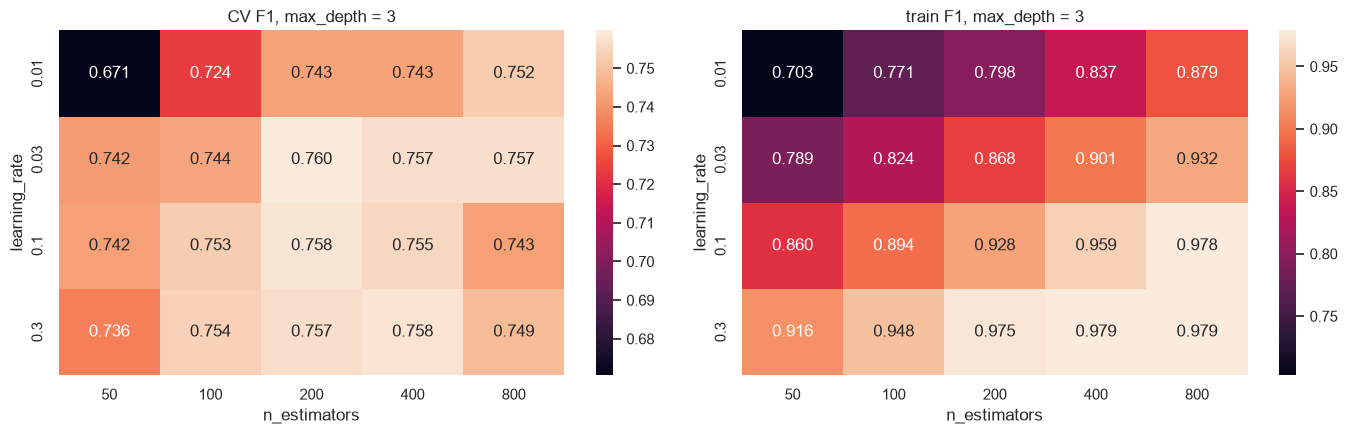

In [18]:
depth3 = grid_table[grid_table["max_depth"] == 3]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, col in zip(axes, ["CV F1", "train F1"]):
    sns.heatmap(depth3.pivot(index="learning_rate", columns="n_estimators", values=col),
                annot=True, fmt=".3f", ax=ax)
    ax.set_title(f"{col}, max_depth = 3")
    ax.set_xlabel("n_estimators")
    ax.set_ylabel("learning_rate")
plt.tight_layout()
plt.show()

**Вывод:**
- **Шаг и число деревьев действуют в одну сторону:** train F1 растёт и вправо (больше деревьев), и вниз (больше шаг). Поэтому подбирать их нужно вместе: маленький шаг можно возместить числом деревьев.
- **Угол недообучения** - левый верхний (шаг 0.01, 50 деревьев): 0.703 на train и 0.671 на CV.
- **Угол переобучения** - правый нижний (шаг 0.1-0.3, 800 деревьев): train F1 на потолке 0.979, а CV снижается до 0.743-0.749.
- **Лучшие клетки** (CV F1 0.757-0.760) - в середине карты, между углами. Хорошая область широкая, поэтому точное значение параметров не так важно, как то, чтобы не попасть в углы.

### 8.5. Итог: области недообучения и переобучения

| Гиперпараметр | Недообучение | Разумная сложность | Переобучение |
|---|---|---|---|
| `n_estimators` (глубина 3) | первые 2-20 деревьев, тем больше, чем меньше шаг: F1 от 0 до 0.70 | примерно 50-500 деревьев: CV F1 0.75-0.77 | сотни деревьев при большом шаге: train 0.979, CV падает до 0.745 |
| `learning_rate` (100 деревьев, глубина 1) | 0.001-0.01: F1 от 0 до 0.71 | 0.03-0.3: CV F1 до 0.771 | 1.0: train 0.837, CV 0.760 (слабое) |
| `max_depth` (100 деревьев, шаг 0.3) | нет: уже глубина 1 лучшая | 1 | 2 и больше: train до 0.979, CV 0.73-0.76 |

- На этих данных недообучение проявляется резко (F1 падает до 0), а переобучение - мягко: CV теряет 0.02-0.04. Главные закономерности (пол, класс) модель ловит с первых деревьев, а лишние деревья подгоняют мелкие детали, которые касаются немногих пассажиров.
- Границы областей для одного параметра зависят от остальных: при маленьком шаге можно больше деревьев и глубже деревья. Поэтому параметры подбирались вместе, а не по одному.

## 9. Анализ устойчивости

### 9.1. F1 на отдельных фолдах
Сравниваем три модели: baseline, лучшую модель Grid Search и лучшую модель Random Search. Фолды у всех одни и те же, поэтому их можно сравнивать попарно: на каждом фолде модели проверялись на одних и тех же пассажирах.

,фолд 1,фолд 2,фолд 3,фолд 4,фолд 5
Baseline,0.7963,0.7170,0.7475,0.6923,0.7677
Grid Search,0.7706,0.7358,0.8235,0.7304,0.7961
Random Search,0.7818,0.7358,0.8077,0.7434,0.7843


,среднее,std,мин,макс,размах,лучше baseline на фолдах
Baseline,0.7441,0.0366,0.6923,0.7963,0.1040,0
Grid Search,0.7713,0.0354,0.7304,0.8235,0.0931,4
Random Search,0.7706,0.0270,0.7358,0.8077,0.0718,4


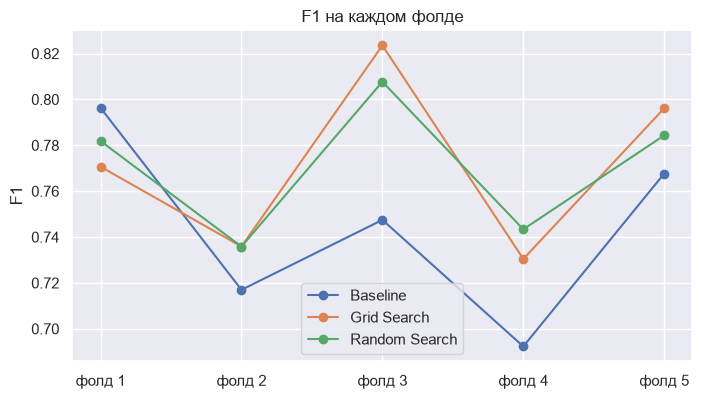

In [19]:
def best_fold_scores(search):
    # F1 лучшей комбинации поиска на каждом из 5 фолдов
    return np.array([search.cv_results_[f"split{k}_test_score"][search.best_index_] for k in range(N_FOLDS)])


fold_names = [f"фолд {i + 1}" for i in range(N_FOLDS)]
folds = pd.DataFrame({
    "Baseline": baseline_cv["test_score"],
    "Grid Search": best_fold_scores(grid_search),
    "Random Search": best_fold_scores(random_search),
}, index=fold_names)

stability = pd.DataFrame({
    "среднее": folds.mean(),
    "std": folds.std(ddof=0),  # как в GridSearchCV
    "мин": folds.min(),
    "макс": folds.max(),
    "размах": folds.max() - folds.min(),
    "лучше baseline на фолдах": [(folds[name] > folds["Baseline"]).sum() for name in folds.columns],
})
display(folds.T.round(4))
display(stability.round(4))

ax = folds.plot(marker="o", figsize=(8, 4.3))
ax.set_xticks(range(N_FOLDS))
ax.set_xticklabels(fold_names)
ax.set_ylabel("F1")
ax.set_title("F1 на каждом фолде")
plt.show()

**Вывод:**
- Grid и Random лучше baseline на 4 фолдах из 5, только на фолде 1 baseline выше.
- Размах между лучшим и худшим фолдом у всех большой - 0.07-0.10. Фолды 2 и 4 самые трудные для всех трёх моделей. Значит, большая часть разброса зависит от того, какие пассажиры попали в фолд, а не от модели.
- По std модели близки (0.027-0.037): подбор не сделал модель заметно стабильнее.

**Две модели с почти одинаковым средним.** Сравним лучшую модель Grid Search со вторым местом той же сетки.

In [20]:
second = grid_table.iloc[1]  # второе место Grid Search
SECOND_PARAMS = {"n_estimators": int(second["n_estimators"]), "learning_rate": float(second["learning_rate"]),
                 "max_depth": int(second["max_depth"])}
second_idx = grid_table.index[1]  # номер этой комбинации в cv_results_

pair = pd.DataFrame({
    "Grid, 1-е место (100 / 0.3 / 1)": best_fold_scores(grid_search),
    "Grid, 2-е место (100 / 0.1 / 4)": [grid_search.cv_results_[f"split{k}_test_score"][second_idx] for k in range(N_FOLDS)],
}, index=fold_names).T
pair["среднее"] = pair[fold_names].mean(axis=1)
pair["std"] = pair[fold_names].std(axis=1, ddof=0)
print("Параметры второго места:", SECOND_PARAMS)
pair.round(4)

Параметры второго места: {'n_estimators': 100, 'learning_rate': 0.1, 'max_depth': 4}


,фолд 1,фолд 2,фолд 3,фолд 4,фолд 5,среднее,std
"Grid, 1-е место (100 / 0.3 / 1)",0.7706,0.7358,0.8235,0.7304,0.7961,0.7713,0.0354
"Grid, 2-е место (100 / 0.1 / 4)",0.7778,0.7568,0.7800,0.7736,0.7525,0.7681,0.0113


**Вывод:**
- Средние почти равны (0.771 и 0.768), но второе место втрое стабильнее: F1 от 0.75 до 0.78 на всех фолдах, а у первого - от 0.73 до 0.82.
- Почему так бывает: в каждом фолде всего около 55 выживших, и несколько трудных пассажиров в одном фолде заметно сдвигают F1. Модели устроены по-разному (деревья глубины 1 и глубины 4) и ошибаются на разных пассажирах, поэтому их F1 по-разному зависит от того, кто попал в фолд.
- При равном среднем лучше модель с меньшим разбросом: её результат на новых данных предсказуемее. Но std по 5 числам - грубая оценка, поэтому проверим, сохраняется ли разница на других разбиениях.

### 9.2. Проверка на других разбиениях
Все результаты выше получены на одном разбиении train на 5 фолдов (зерно 42). Проверим те же модели на 10 других разбиениях (зёрна 1-10). Это не подбор: модели и их параметры уже выбраны, мы только смотрим, насколько их оценки зависят от того, как train разрезан на фолды. Test по-прежнему не используется.

,наше разбиение (42),среднее по 10 другим,мин,макс,std между фолдами (в среднем),лучше baseline (из 10)
Baseline,0.7441,0.7694,0.7570,0.7856,0.0372,0
Grid Search,0.7713,0.7555,0.7466,0.7628,0.0393,2
Random Search,0.7706,0.7558,0.7475,0.7652,0.0374,1
"Grid, 2-е место",0.7681,0.7671,0.7404,0.7898,0.0382,5


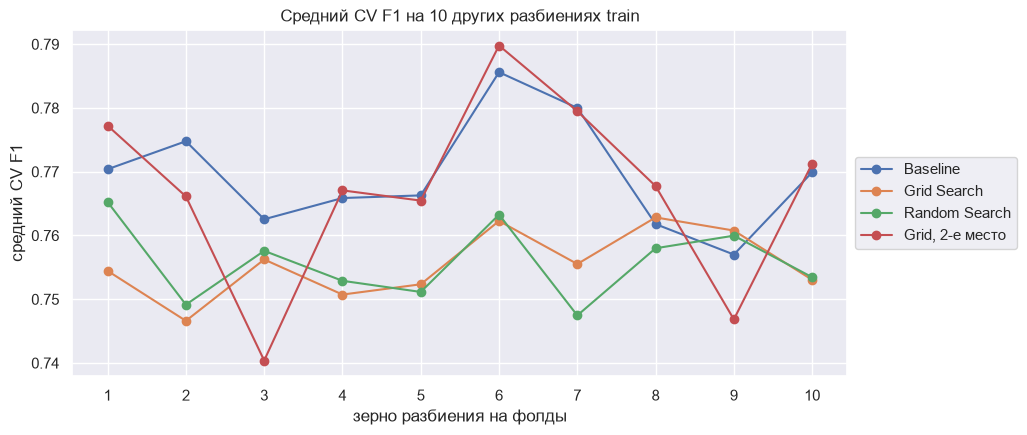

In [21]:
CHECK_SEEDS = range(1, 11)  # 10 других разбиений train на 5 фолдов
RANDOM_BEST = {name.replace("model__", ""): value for name, value in random_search.best_params_.items()}
check_models = {
    "Baseline": BASELINE_PARAMS,
    "Grid Search": GRID_BEST,
    "Random Search": RANDOM_BEST,
    "Grid, 2-е место": SECOND_PARAMS,
}

split_means = {name: [] for name in check_models}  # средний CV F1 на каждом разбиении
fold_stds = {name: [] for name in check_models}    # разброс между фолдами внутри разбиения
for seed in CHECK_SEEDS:
    other_cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=seed)
    for name, params in check_models.items():
        scores = cross_val_score(make_gb(**params), X_train, y_train, cv=other_cv, scoring=F1, n_jobs=N_JOBS)
        split_means[name].append(scores.mean())
        fold_stds[name].append(scores.std())
split_means = pd.DataFrame(split_means, index=[f"зерно {seed}" for seed in CHECK_SEEDS])

our_split = {"Baseline": baseline_f1, "Grid Search": grid_search.best_score_,
             "Random Search": random_search.best_score_, "Grid, 2-е место": grid_table.iloc[1]["CV F1"]}
check_table = pd.DataFrame({
    "наше разбиение (42)": pd.Series(our_split),
    "среднее по 10 другим": split_means.mean(),
    "мин": split_means.min(),
    "макс": split_means.max(),
    "std между фолдами (в среднем)": pd.Series({name: np.mean(v) for name, v in fold_stds.items()}),
    "лучше baseline (из 10)": pd.Series({name: (split_means[name] > split_means["Baseline"]).sum()
                                         for name in check_models}),
})
display(check_table.round(4))

ax = split_means.plot(marker="o", figsize=(10, 4.5))
ax.set_xticks(range(len(split_means)))
ax.set_xticklabels([str(seed) for seed in CHECK_SEEDS])
ax.set_xlabel("зерно разбиения на фолды")
ax.set_ylabel("средний CV F1")
ax.set_title("Средний CV F1 на 10 других разбиениях train")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.show()

**Вывод:**
- **Подобранные модели не лучше baseline.** На 10 других разбиениях baseline в среднем даёт 0.769, а лучшие модели Grid и Random - 0.756. Grid лучше baseline только на 2 разбиениях из 10, Random - на 1.
- **Почему так вышло.** Наше разбиение оказалось неудачным для baseline: 0.744 - ниже, чем на любом из 10 других (0.757-0.786). А лучшая комбинация Grid на нашем разбиении получила 0.771 - выше, чем на любом другом (0.747-0.763). Поиск выбрал из 100 вариантов тот, которому повезло именно на этих 5 фолдах. Это подгонка под фолды - тот же эффект, что при выборе по test (раздел 3.1), только слабее.
- **Устойчивость второго места не подтвердилась:** на других разбиениях разброс между фолдами у всех моделей одинаковый, около 0.038. Маленький std на наших фолдах был случайностью.
- **Итог:** на этих данных параметры baseline уже были близки к лучшим, и реальный выигрыш от подбора меньше шума оценки. Надёжнее было бы подбирать по повторной кросс-валидации (сразу по нескольким разбиениям): это в несколько раз дольше, зато меньше подгонки под одно разбиение.

### Правило выбора финальной модели (зафиксировано до test)
- Финальная модель - **лучшая модель Grid Search** (100 деревьев, шаг 0.3, глубина 1): её выбрала процедура подбора, заданная заранее (раздел 6). Менять выбор после проверки 9.2 не будем - это был бы ещё один выбор задним числом.
- На test в разделе 10 оцениваем все три модели (baseline, Grid, Random) один раз. После проверки 9.2 ожидаем, что подобранные модели на test будут не лучше baseline.

## 10. Финальная модель и test
Подбор закончен, правило выбора финальной модели записано в разделе 9. Теперь все три модели обучены на всём train, и test используется **первый и единственный раз**. После этого ничего не меняем.

### 10.1. Оценка на test

In [22]:
baseline.fit(X_train, y_train)  # в разделе 4 baseline проверялся только кросс-валидацией, теперь учим на всём train
final_models = {
    "Baseline": baseline,
    "Grid Search": grid_search.best_estimator_,      # refit=True: уже обучена на всём train
    "Random Search": random_search.best_estimator_,  # тоже
}
cv_ours = {"Baseline": baseline_f1, "Grid Search": grid_search.best_score_, "Random Search": random_search.best_score_}

# test используется здесь первый и единственный раз
test_pred = {name: model.predict(X_test) for name, model in final_models.items()}

rows = {}
for name, model in final_models.items():
    pred = test_pred[name]
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    rows[name] = {
        "train F1": f1_score(y_train, model.predict(X_train)),
        "CV F1 (наше разбиение)": cv_ours[name],
        "CV F1 (10 других разбиений)": split_means[name].mean(),
        "test F1": f1_score(y_test, pred),
        "test Precision": precision_score(y_test, pred),
        "test Recall": recall_score(y_test, pred),
        "test Accuracy": accuracy_score(y_test, pred),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
    }
final_table = pd.DataFrame(rows).T
final_table[["TN", "FP", "FN", "TP"]] = final_table[["TN", "FP", "FN", "TP"]].astype(int)
final_table.round(4)

,train F1,CV F1 (наше разбиение),CV F1 (10 других разбиений),test F1,test Precision,test Recall,test Accuracy,TN,FP,FN,TP
Baseline,0.8795,0.7441,0.7694,0.7460,0.8246,0.6812,0.8212,100,10,22,47
Grid Search,0.7805,0.7713,0.7555,0.7556,0.7727,0.7391,0.8156,95,15,18,51
Random Search,0.7865,0.7706,0.7558,0.7737,0.7794,0.7681,0.8268,95,15,16,53


**Вывод:**
- По test F1 подобранные модели немного лучше baseline: Grid - 0.756 (+0.010), Random - 0.774 (+0.028). У baseline 0.746 - столько же, сколько у бустинга в лабораторной №2.
- Но по числу ошибок модели почти равны: baseline ошибся 32 раза из 179, Grid - 33, Random - 31. По Accuracy Grid даже чуть хуже baseline (0.816 против 0.821).
- F1 у подобранных моделей выше, потому что они чаще говорят "выжил". Они находят больше выживших (Recall 0.74-0.77 против 0.68), но и чаще ошибочно "спасают" погибших (FP 15 против 10). Верно угаданных погибших F1 не учитывает, поэтому такой обмен ему выгоден.

In [23]:
# на скольких пассажирах test модели отвечают по-разному и кто из них в этих случаях прав
y_true = y_test.to_numpy()
for first, second in [("Baseline", "Grid Search"), ("Baseline", "Random Search"), ("Grid Search", "Random Search")]:
    differ = test_pred[first] != test_pred[second]
    first_right = (test_pred[first][differ] == y_true[differ]).sum()
    print(f"{first} и {second}: разные ответы у {differ.sum()} из {len(y_test)} пассажиров, "
          f"прав {first} - {first_right}, прав {second} - {differ.sum() - first_right}")

Baseline и Grid Search: разные ответы у 21 из 179 пассажиров, прав Baseline - 11, прав Grid Search - 10
Baseline и Random Search: разные ответы у 23 из 179 пассажиров, прав Baseline - 11, прав Random Search - 12
Grid Search и Random Search: разные ответы у 2 из 179 пассажиров, прав Grid Search - 0, прав Random Search - 2


**Вывод:**
- Baseline и Grid отвечают по-разному на 21 пассажире, и правы почти поровну: 11 и 10. С Random то же самое: 11 и 12. Значит, на test модели различаются на 1-2 пассажира из 179.
- Grid и Random почти одинаковые модели (деревья глубины 1 с большим шагом): разные ответы только у 2 пассажиров. Эти два пассажира и дают всю разницу их F1 (0.756 и 0.774) - один пассажир на test весит около 0.01 F1.

### 10.2. CV и test

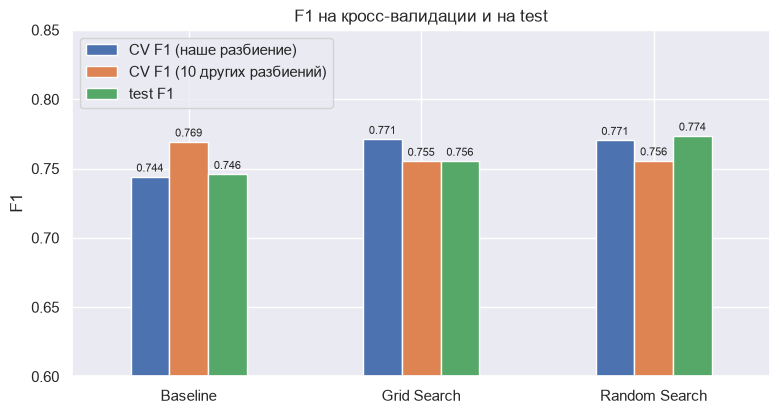

In [24]:
ax = final_table[["CV F1 (наше разбиение)", "CV F1 (10 других разбиений)", "test F1"]].plot.bar(figsize=(9, 4.5), rot=0)
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.3f", fontsize=8, padding=2)
ax.set_ylim(0.6, 0.85)
ax.set_ylabel("F1")
ax.set_title("F1 на кросс-валидации и на test")
ax.legend(loc="upper left")
plt.show()

**Вывод:**
- На нашем разбиении CV обещала обеим подобранным моделям +0.027. На test вышло +0.010 и +0.028, а на 10 других разбиениях CV показывала -0.014. Три оценки одного и того же расходятся на 0.04.
- Прогноз из раздела 9 подтвердился частично: по F1 подобранные модели на test чуть выше baseline, но по числу верных ответов они с ним равны.

### 10.3. Ответы на вопросы ТЗ
**Насколько оптимизация гиперпараметров улучшила качество.** На test F1 вырос на 0.010 (Grid) и 0.028 (Random), а Accuracy изменилась на -0.006 и +0.006. В пассажирах это от -1 до +1 верного ответа из 179. Честный ответ: заметного улучшения нет. Подбор в основном сдвинул баланс в сторону Recall (модель чаще говорит "выжил"), а лучше различать пассажиров модель не стала.

**Совпадает ли улучшение на кросс-валидации с результатом на test.** Нет. CV на нашем разбиении обещала обеим моделям одинаковый прирост +0.027. На test Grid дал +0.010, Random +0.028, а между собой эти модели, равные по CV, разошлись на 0.018. На других разбиениях CV вообще показывала, что подобранные модели хуже baseline.

**Чем это объяснить.**
- **Оценка лучшей комбинации завышена.** Из 100 вариантов на одних и тех же фолдах побеждает тот, которому на них повезло (раздел 9.2). Чем больше вариантов перебираем, тем сильнее завышение.
- **Наше разбиение было неудачным для baseline:** 0.744 против 0.769 в среднем на других разбиениях. Поэтому прирост на CV казался больше, чем есть на самом деле.
- **Test маленький:** 179 пассажиров, из них 69 выживших. Один пассажир меняет F1 примерно на 0.01, так что разница в 0.01-0.03 - это 1-3 человека, то есть шум.
- **Качество упирается в данные, а не в гиперпараметры.** У части пассажиров одинаковые признаки и разный исход (лабораторная №2), а все разумные настройки бустинга дают примерно одно и то же - широкое плато в разделе 8.

## 11. Сохранение модели
По правилу из раздела 9 сохраняем лучшую модель Grid Search - целиком, вместе с предобработкой, потому что новые данные приходят "сырыми". Модель обучена только на train. Открывать файл нужно той же версией scikit-learn (у нас 1.9.1).

In [25]:
final_model = grid_search.best_estimator_  # Pipeline: предобработка + бустинг (100 деревьев, шаг 0.3, глубина 1)
joblib.dump(final_model, MODEL_PATH)
print(f"Сохранено: {MODEL_PATH} ({MODEL_PATH.stat().st_size / 1e3:.0f} КБ)")

# проверка: модель из файла даёт те же прогнозы для пассажиров, заново прочитанных из исходного CSV
loaded_model = joblib.load(MODEL_PATH)
new_data = pd.read_csv(DATA_PATH).loc[X_test.index]   # сырые строки в формате Kaggle
loaded_pred = loaded_model.predict(make_features(new_data))
assert (loaded_pred == test_pred["Grid Search"]).all()
print("Параметры:", {k: loaded_model.named_steps["model"].get_params()[k] for k in GRID_BEST})
print(f"F1 модели из файла на этих пассажирах: {f1_score(new_data[TARGET], loaded_pred):.4f} - как в разделе 10")

Сохранено: model.joblib (60 КБ)
Параметры: {'learning_rate': 0.3, 'max_depth': 1, 'n_estimators': 100}
F1 модели из файла на этих пассажирах: 0.7556 - как в разделе 10


## 12. Итоги
- **Модель и baseline:** Gradient Boosting на данных Титаника из лабораторной №2. Baseline - параметры из лабораторной №2 (200 деревьев, шаг 0.05, глубина 3): CV F1 0.744, test F1 0.746.
- **Подбор:** три гиперпараметра (`n_estimators`, `learning_rate`, `max_depth`), 5-fold кросс-валидация только на train. Grid Search и Random Search (по 100 комбинаций, меньше минуты каждый) нашли одну и ту же область - деревья глубины 1 с большим шагом, CV F1 0.771.
- **Grid или Random:** качество одинаковое, но Random просмотрел пространство подробнее (100 разных шагов против 4) и вышел на хороший результат уже за 10-20 итераций. Дольше он считал только из-за большего среднего числа деревьев.
- **Влияние гиперпараметров:** недообучение - мало деревьев или очень маленький шаг (F1 вплоть до 0); переобучение - много деревьев при большом шаге или глубокие деревья (train F1 0.979, CV падает на 0.02-0.04); между ними широкое плато.
- **Устойчивость:** разброс между фолдами (std около 0.035) больше, чем выигрыш от подбора. На других разбиениях train подобранные модели не лучше baseline - поиск подстроился под конкретные фолды.
- **Test (один раз):** baseline 0.746, Grid 0.756, Random 0.774. По числу ошибок модели равны (31-33 из 179). Параметры baseline уже были близки к лучшим, и на 712 пассажирах подбор гиперпараметров качество заметно не улучшает. Для более надёжного подбора стоит использовать повторную кросс-валидацию по нескольким разбиениям.